# EDA — Jinan training flow (ROADMAP 3.3, guidelines G5)

**Train split only.** This notebook reads one flow file, `anon_3_4_jinan_real.json`
(Jinan *train*), and simulator traces generated from it. The validation and test flows and
the held-out city are not loaded: `train_flow()` raises for any other split, and
`tests/data/test_trace.py` scans this notebook for other file or split names.

**How to reproduce**

```bash
python scripts/audit_data.py                                   # docs/data_audit.json
python scripts/collect_traces.py --config configs/eda.yaml     # results/eda/ (train flow only)
jupyter nbconvert --to notebook --execute --inplace notebooks/01_eda_train.ipynb
```

A flow file contains only *demand* (when each vehicle enters and which roads it takes).
Queues, pressure and travel times exist only once something operates the signals, so those
are shown under three simple rule controllers, each run on the training flow:
**Fixed-Time** (30 s per phase, cyclic), **Max-Pressure** (decision every 10 s) and
**Random phase** (uniform-random phase every 10 s — the regime an untrained, exploring RL
agent starts in). These are descriptive rollouts, not the baseline results of Phase 4.

Figures are saved to `docs/figures/eda/`. Each figure is followed by a short interpretation;
the last section lists the insights that shaped later choices.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from trafficrl.data import eda
from trafficrl.data.audit import arrival_counts
from trafficrl.data.roadnet import DIRECTIONS, load_roadnet
from trafficrl.data.splits import REPO_ROOT
from trafficrl.data.trace import train_flow
from trafficrl.envs.features import FeatureBuilder, FeatureSpec
from trafficrl.utils.config import load_config
from trafficrl.utils.plotting import (
    BLUE, BLUE_RAMP, CONTROLLER_COLOR, CONTROLLER_LABEL, INK, INK_SECONDARY, MUTED, ORANGE,
    apply_style, save_figure,
)

apply_style()
pd.options.display.float_format = lambda x: f"{x:,.0f}" if float(x).is_integer() else f"{x:,.2f}"

cfg = load_config(REPO_ROOT / "configs" / "eda.yaml")
roadnet_path, flow_path = train_flow(cfg)      # raises unless primary dataset / train split
roadnet = load_roadnet(roadnet_path)
raw_roadnet = json.loads(roadnet_path.read_text())
flows = json.loads(flow_path.read_text())
features = FeatureBuilder(roadnet, FeatureSpec.from_config(cfg))

EPISODE = cfg["sim"]["episode_seconds"]
BIN = cfg["eda"]["arrival_bin_seconds"]
FIG = REPO_ROOT / "docs" / "figures" / "eda"
TRACES = REPO_ROOT / cfg["output"]["results_dir"]
SEQ = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)

# one trace per controller (seed 0) for the distribution plots
RUN_NAME = {"fixed_time": "fixed_time_dt30_seed0", "max_pressure": "max_pressure_dt10_seed0",
            "random": "random_dt10_seed0"}
runs = {c: eda.load_run(TRACES / name) for c, name in RUN_NAME.items()}
summaries = eda.load_summaries(TRACES)
print(flow_path.name, "-", len(flows), "vehicles;", len(summaries), "trace runs")

anon_3_4_jinan_real.json - 6295 vehicles; 12 trace runs


## 1. Sample counts and summary statistics

In [2]:
moves = eda.movement_demand(flows, roadnet)
lengths = eda.route_lengths(flows)
crossings = eda.signalised_crossings(flows, roadnet)
counts = arrival_counts(flows, EPISODE, BIN)
cap = pd.Series(features.capacity)

table1 = pd.Series({
    "vehicles (trips) in the hour": len(flows),
    "episode length (s)": EPISODE,
    "signalised intersections (agents)": len(roadnet.intersections),
    "boundary (virtual) nodes": len(roadnet.virtual_ids),
    "roads": len(roadnet.road_ids),
    "lanes": len(roadnet.lane_length_m),
    "incoming lanes per intersection": 12,
    "green phases per intersection (actions)": len(roadnet.green_phase_ids),
    "distinct routes": len({tuple(v["route"]) for v in flows}),
    "roads per route: mean": lengths.mean(),
    "roads per route: median": lengths.median(),
    "roads per route: max": lengths.max(),
    "signalised intersections crossed per trip: mean": crossings.mean(),
    "signalised intersections crossed per trip: max": crossings.max(),
    f"arrivals per {BIN} s: mean": counts.mean(),
    f"arrivals per {BIN} s: min": counts.min(),
    f"arrivals per {BIN} s: max": counts.max(),
    "lane capacity (vehicles): 400 m lanes": cap.min(),
    "lane capacity (vehicles): 800 m lanes": cap.max(),
}, name="Jinan train flow")
display(table1.to_frame())
print("crossings per trip:", crossings.value_counts().sort_index().to_dict())

,Jinan train flow
vehicles (trips) in the hour,"6,295"
episode length (s),"3,600"
signalised intersections (agents),12
boundary (virtual) nodes,14
roads,62
lanes,186
incoming lanes per intersection,12
green phases per intersection (actions),8
distinct routes,860
roads per route: mean,4.37


crossings per trip: {1: 971, 2: 1230, 3: 1533, 4: 1202, 5: 633, 6: 357, 7: 155, 8: 100, 9: 54, 10: 24, 11: 16, 12: 9, 13: 6, 14: 3, 15: 1, 16: 1}


*Table 1. Size of the training scenario and of the road network. Capacity = lane length / 7.5 m (vehicle length 5 m + minimum gap 2.5 m).*

**Interpretation.** The training scenario is one hour with 6,295 vehicles on 12 signalised
intersections, following 860 distinct routes. A trip crosses 3.4 signalised intersections on
average (median 3; 15 % cross only one), so a vehicle's travel time is decided by a handful of
signals. With a decision every 10 s, one episode gives 360 decisions × 12 intersections =
4,320 state samples. A lane holds at most 53 vehicles (400 m roads) or 106 (800 m roads); this
capacity is the only constant used to normalise the observations.

## 2. Road network

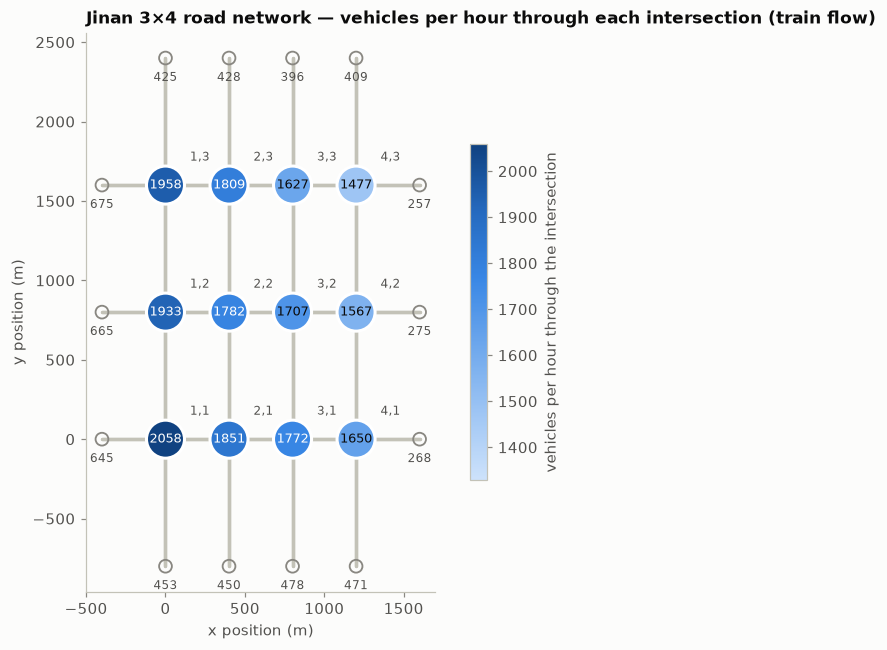

In [3]:
load = eda.intersection_load(moves)
entry = eda.entry_demand(flows)
pos = {i["id"]: (i["point"]["x"], i["point"]["y"]) for i in raw_roadnet["intersections"]}

fig, ax = plt.subplots(figsize=(8.2, 6.6))
for r in raw_roadnet["roads"]:
    (x0, y0), (x1, y1) = pos[r["startIntersection"]], pos[r["endIntersection"]]
    ax.plot([x0, x1], [y0, y1], color="#c3c2b7", linewidth=2.2, zorder=1, solid_capstyle="round")
sig = list(roadnet.intersections)
sc = ax.scatter([pos[i][0] for i in sig], [pos[i][1] for i in sig], c=[load[i] for i in sig],
                cmap=SEQ, s=620, zorder=3, edgecolors="white", linewidths=2,
                vmin=load.min() * 0.9, vmax=load.max())
for i in sig:
    ax.annotate(f"{load[i]}", pos[i], ha="center", va="center", fontsize=8.5, zorder=4,
                color="white" if load[i] > load.mean() else INK)
    ax.annotate(i.removeprefix("intersection_").replace("_", ","), pos[i], xytext=(16, 16),
                textcoords="offset points", fontsize=8, color=INK_SECONDARY)
for v in roadnet.virtual_ids:
    x, y = pos[v]
    ax.scatter([x], [y], s=70, facecolors="none", edgecolors=MUTED, linewidths=1.2, zorder=3)
    road = next(r for r in roadnet.road_ids if roadnet.road_start[r] == v)
    ax.annotate(f"{entry.get(road, 0)}", (x, y), xytext=(0, -15), textcoords="offset points",
                ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_aspect("equal")
ax.grid(False)
ax.set(title="Jinan 3×4 road network — vehicles per hour through each intersection (train flow)",
       xlabel="x position (m)", ylabel="y position (m)")
fig.colorbar(sc, ax=ax, shrink=0.6, label="vehicles per hour through the intersection")
save_figure(fig, FIG / "02_network.png")
plt.show()

*Figure 2. Road network. Filled circles: the 12 signalised intersections (one agent each), labelled x,y and coloured by the number of vehicles that pass through in the hour (number inside). Open circles: boundary nodes where vehicles enter and leave; the number below each is the vehicles per hour entering there. East–west spacing 400 m, north–south 800 m.*

**Interpretation.** The network is a regular 4 × 3 grid. Demand is not uniform: the three
western entries bring 645–675 vehicles per hour each, the three eastern entries only 257–275,
while the northern and southern entries are similar to each other (396–478). As a result the
load falls from about 2,000 vehicles per hour in the western column to about 1,500–1,650 in the
eastern column (factor 1.4). The 12 agents therefore face different conditions, and what
arrives at an intersection depends on what its western neighbour releases. This is the
situation in which neighbour information (the attention module) can be useful; whether it
actually helps is tested by the −attention ablation, not shown here.

## 3. Demand over time (the input the controller must handle)

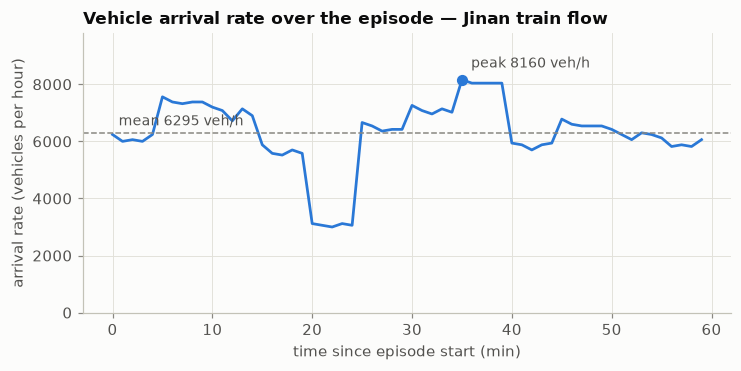

arrivals per minute within each 5-minute block (min-max): ['100-104', '122-126', '112-120', '92-98', '50-52', '106-111', '116-121', '134-136', '95-99', '109-113', '101-107', '97-102']


In [4]:
minutes = np.arange(len(counts)) * BIN / 60
fig, ax = plt.subplots(figsize=(7.6, 3.3))
ax.plot(minutes, counts * 3600 / BIN, color=BLUE)
peak = counts.argmax()
ax.scatter([minutes[peak]], [counts[peak] * 3600 / BIN], color=BLUE, s=40, zorder=3)
ax.annotate(f"peak {counts[peak] * 3600 // BIN} veh/h", (minutes[peak], counts[peak] * 3600 / BIN),
            xytext=(6, 8), textcoords="offset points", fontsize=9, color=INK_SECONDARY)
ax.axhline(len(flows) * 3600 / EPISODE, color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"mean {len(flows) * 3600 // EPISODE} veh/h", (0, len(flows) * 3600 / EPISODE),
            xytext=(4, 5), textcoords="offset points", fontsize=9, color=INK_SECONDARY)
ax.set(title="Vehicle arrival rate over the episode — Jinan train flow",
       xlabel="time since episode start (min)", ylabel="arrival rate (vehicles per hour)",
       ylim=(0, counts.max() * 3600 / BIN * 1.2))
save_figure(fig, FIG / "03_arrival_rate.png")
plt.show()
five = counts.reshape(-1, 5)
print("arrivals per minute within each 5-minute block (min-max):",
      [f"{a}-{b}" for a, b in zip(five.min(axis=1), five.max(axis=1))])

*Figure 3. Arrival rate (vehicles entering the network, per minute, expressed per hour). Dashed line: mean over the hour.*

**Interpretation.** Demand averages 6,295 vehicles per hour but is not constant: it peaks at
8,160 vehicles per hour (minutes 35–39) and drops to about 3,000 (minutes 20–24), a factor of
2.7. The curve is step-shaped: within each five-minute block the per-minute count varies by at
most 8 vehicles, which suggests the released trips were generated from five-minute counts. Two
consequences. First, the arrival rate is nearly constant over a 10 s decision interval, so
short-term changes in the state come from the signals, not from demand noise. Second, one
episode contains several demand levels, including a sudden drop and recovery, so a controller
that adapts should gain over a fixed plan.

## 4. Outcome distribution: travel time under rule controllers

RL has no labels. The quantity the project optimises is vehicle travel time, so its
distribution under Fixed-Time stands in for the guidelines' target histogram.

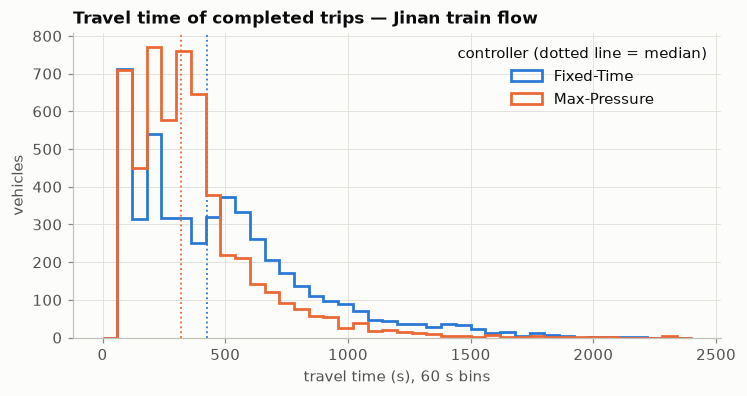

,completed trips,not completed,of which never entered,median (s),"mean, completed (s)",p95 (s),max (s),CityFlow average travel time (s)
Fixed-Time,"4,969","1,326",234,427,486.38,"1,213","2,566",515.21
Max-Pressure,"5,446",849,0,320,366.09,851.75,"2,736",374.94


In [5]:
fig, ax = plt.subplots(figsize=(7.6, 3.6))
bins = np.arange(0, 2401, 60)
rows = {}
for c in ("fixed_time", "max_pressure"):
    v = runs[c]["vehicles"]
    done = v["travel_time"].dropna()
    ax.hist(done, bins=bins, histtype="step", linewidth=1.8, color=CONTROLLER_COLOR[c],
            label=CONTROLLER_LABEL[c])
    ax.axvline(done.median(), color=CONTROLLER_COLOR[c], linestyle=":", linewidth=1.2)
    s = runs[c]["summary"]
    rows[CONTROLLER_LABEL[c]] = {
        "completed trips": len(done), "not completed": len(v) - len(done),
        "of which never entered": s["never_entered"],
        "median (s)": done.median(), "mean, completed (s)": done.mean(),
        "p95 (s)": done.quantile(0.95), "max (s)": done.max(),
        "CityFlow average travel time (s)": s["avg_travel_time_s"],
    }
ax.set(title="Travel time of completed trips — Jinan train flow",
       xlabel="travel time (s), 60 s bins", ylabel="vehicles")
ax.legend(title="controller (dotted line = median)")
save_figure(fig, FIG / "04_travel_time.png")
plt.show()
display(pd.DataFrame(rows).T)

*Figure 4 and Table 4. Travel time (exit time − planned start time) of the trips completed within the 3600 s episode. "CityFlow average travel time" is the simulator's own metric, which also counts the time so far of vehicles still in the network at the end.*

**Interpretation.** Travel time is right-skewed under both controllers: the median is 427 s
(Fixed-Time) and 320 s (Max-Pressure), but the 95th percentile is 1,210 s and 852 s and single
trips exceed 2,500 s. Not every trip finishes within the hour: 1,326 vehicles (21 %) under
Fixed-Time, 234 of which could not even enter because their entry lane was full, and 849
(13 %) under Max-Pressure. Because of the skew and the unfinished trips, the mean travel time
alone is an incomplete summary. The evaluation should therefore also report throughput
(completed trips) and a tail measure such as the maximum wait. Max-Pressure shifts the whole
distribution left compared with Fixed-Time (average 375 s vs. 515 s, the same values as the
install benchmark in worklog/007).

## 5. Missing values and data quality (from the audit)

In [6]:
audit = json.loads((REPO_ROOT / "docs" / "data_audit.json").read_text())
train = audit["datasets"]["jinan"]["flows"][flow_path.name]
assert train["split"] == "train"
info_keys = ["records", "vehicle_profiles", "route_ends_inside_network",
             "route_revisits_intersection", "arrival_burst_bins", "arrival_low_bins",
             "same_second_same_entry_lane"]
defect_counts = {k: v for k, v in train.items() if k not in info_keys and k != "split"}
print("defect checks:", len(defect_counts), "| non-zero:", {k: v for k, v in defect_counts.items() if v})
display(pd.Series({k: train[k] for k in ["missing_field", "missing_vehicle_field", "wrong_type",
                                         "duplicate_records"] + info_keys},
                  name="Jinan train flow").to_frame())

defect checks: 17 | non-zero: {}


,Jinan train flow
missing_field,0
missing_vehicle_field,0
wrong_type,0
duplicate_records,0
records,6295
vehicle_profiles,1
route_ends_inside_network,77
route_revisits_intersection,208
arrival_burst_bins,0
arrival_low_bins,5


*Table 5. Missing-value, duplicate and information counts for the training flow, read from `docs/data_audit.json` (full audit of all files: `docs/data_audit.md`).*

**Interpretation.** The training flow has no missing fields, no wrong types and no duplicate
records; all 17 defect checks are zero. Three properties are noted, none of them an error:
77 trips (1.2 %) end inside the network, 208 routes (3.3 %) pass an intersection twice, and
five consecutive minutes (20–24) are low-demand outliers. No record is removed or changed.

## 6. Feature distributions and the capacity normalisation

The observation uses, per incoming lane, the number of vehicles and the number of waiting
vehicles divided by the lane's capacity, and per movement the normalised pressure
(`trafficrl.envs.features`). Below: their distributions over all recorded
(time, intersection, lane) samples, one sample every 10 s.

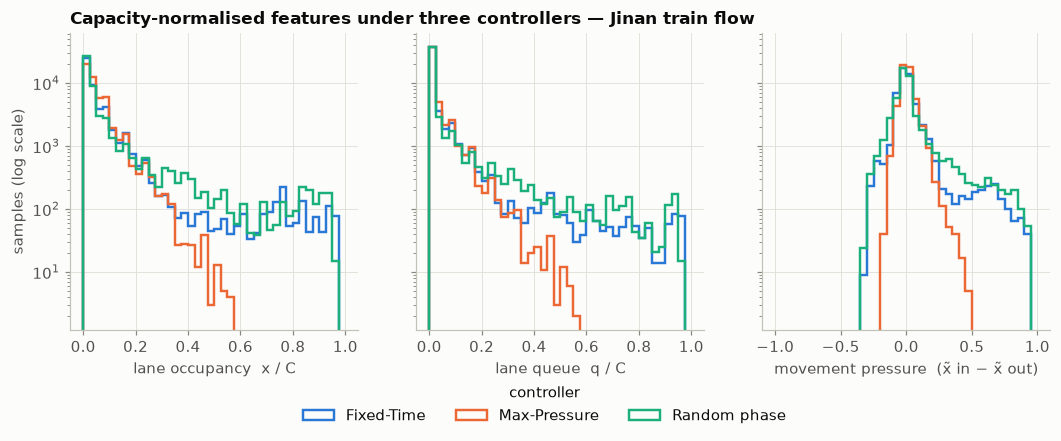

,vehicles/lane: mean,vehicles/lane: p95,vehicles/lane: max,queue/lane: mean,queue/lane: max,x/C: mean,x/C: max,q/C: max,share of samples above 1 (clipped),share of empty lanes (x = 0),pressure: min,pressure: max
Fixed-Time,5.09,22,78,3.00,78,0.07,0.96,0.96,0,0.24,-0.31,0.95
Max-Pressure,3.84,12,32,1.72,30,0.05,0.57,0.57,0,0.15,-0.19,0.49
Random phase,6.22,36,99,4.12,99,0.08,0.96,0.96,0,0.25,-0.32,0.94


Fixed-Time mean queue per lane, by lane type: {'left': 0.79, 'through': 8.18, 'right': 0.01}


In [7]:
arrays = {c: eda.feature_arrays(runs[c]["steps"], features) for c in runs}
panels = [("count_norm", "lane occupancy  x / C", np.linspace(0, 1, 41)),
          ("queue_norm", "lane queue  q / C", np.linspace(0, 1, 41)),
          ("pressure", "movement pressure  (x̃ in − x̃ out)", np.linspace(-1, 1, 41))]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5), sharey=True)
for ax, (key, label, bins) in zip(axes, panels):
    for c in runs:
        ax.hist(arrays[c][key], bins=bins, histtype="step", linewidth=1.6,
                color=CONTROLLER_COLOR[c], label=CONTROLLER_LABEL[c])
    ax.set_yscale("log")
    ax.set(xlabel=label)
axes[0].set(ylabel="samples (log scale)")
axes[0].set_title("Capacity-normalised features under three controllers — Jinan train flow")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="controller", ncols=3, loc="upper center",
           bbox_to_anchor=(0.5, 0.0))
save_figure(fig, FIG / "06_feature_distributions.png")
plt.show()

rows = {}
for c in runs:
    a = arrays[c]
    rows[CONTROLLER_LABEL[c]] = {
        "vehicles/lane: mean": a["count"].mean(), "vehicles/lane: p95": np.percentile(a["count"], 95),
        "vehicles/lane: max": a["count"].max(),
        "queue/lane: mean": a["queue"].mean(), "queue/lane: max": a["queue"].max(),
        "x/C: mean": a["count_norm"].mean(), "x/C: max": a["count_norm"].max(),
        "q/C: max": a["queue_norm"].max(),
        "share of samples above 1 (clipped)": (a["count_norm"] > 1).mean(),
        "share of empty lanes (x = 0)": (a["count"] == 0).mean(),
        "pressure: min": a["pressure"].min(), "pressure: max": a["pressure"].max(),
    }
display(pd.DataFrame(rows).T)

# by lane type (canonical order: left, through, right for each approach)
ft = runs["fixed_time"]["steps"]
kind = np.tile(["left", "through", "right"], 4)
q = ft.filter(regex=r"^queue_").to_numpy()
print("Fixed-Time mean queue per lane, by lane type:",
      {k: round(float(q[:, kind == k].mean()), 2) for k in ("left", "through", "right")})

*Figure 6 and Table 6. Distribution of the three lane/movement features of the observation after capacity normalisation (not clipped, so values above 1 would be visible), under the three rule controllers. Raw per-lane values are in the table.*

**Interpretation.** Most lane samples are close to empty: mean occupancy is 5–8 % of capacity
and 15–26 % of samples are exactly zero. The tail is long: under Fixed-Time and random control
single lanes fill to 96 % of capacity (78–99 vehicles), while under Max-Pressure no lane
exceeds 57 %. No sample exceeds 1 under any controller, so dividing by lane capacity bounds
the inputs to [0, 1] without any fitted statistic, and clipping never acts on the training
traces. Movement pressure stays within [−0.32, 0.95] and is mostly near zero. Queues sit
almost entirely on through lanes (mean 8.2 vehicles under Fixed-Time, against 0.8 on left-turn
lanes and 0.01 on right-turn lanes, which are always green), so the right-turn lane inputs
carry little information. One further point for the method: a well-controlled network visits
only the low-occupancy part of this range. Heavily congested states are rare once a policy is
good, so they are the states where a learned Q-function has the least data; that is the
situation the uncertainty gate is designed for (an expectation to be tested in Phase 7, not a
result).

## 7. Turning ratios

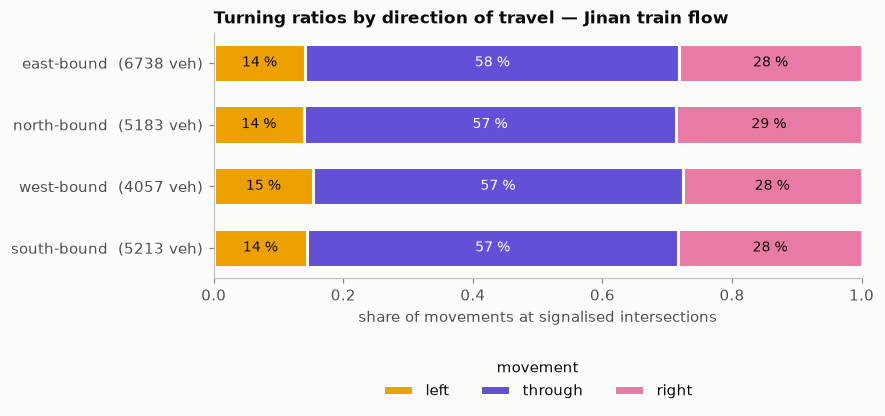

kind,turn_left,go_straight,turn_right
approach,,,
E,14.10,57.80,28.10
N,13.90,57.40,28.60
W,15.30,57.10,27.60
S,14.40,57.30,28.30


In [8]:
ratios = eda.turning_ratios(moves)
KIND = {"turn_left": ("left", "#eda100"), "go_straight": ("through", "#6250d6"),
        "turn_right": ("right", "#e87ba4")}
approach_total = moves.groupby("approach")["vehicles"].sum().reindex(list(DIRECTIONS))
fig, ax = plt.subplots(figsize=(7.6, 2.9))
left = np.zeros(len(ratios))
for k, (label, color) in KIND.items():
    ax.barh(range(len(ratios)), ratios[k], left=left, color=color, label=label, height=0.62,
            edgecolor="#fcfcfb", linewidth=2)
    for y, (x0, w) in enumerate(zip(left, ratios[k])):
        ax.text(x0 + w / 2, y, f"{100 * w:.0f} %", ha="center", va="center", fontsize=9,
                color=INK if k != "go_straight" else "white")
    left += ratios[k].to_numpy()
names = {"E": "east-bound", "N": "north-bound", "W": "west-bound", "S": "south-bound"}
ax.set_yticks(range(len(ratios)))
ax.set_yticklabels([f"{names[d]}  ({approach_total[d]} veh)" for d in ratios.index])
ax.invert_yaxis()
ax.grid(False)
ax.set(title="Turning ratios by direction of travel — Jinan train flow",
       xlabel="share of movements at signalised intersections", xlim=(0, 1))
ax.legend(title="movement", ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.28))
save_figure(fig, FIG / "07_turning_ratios.png")
plt.show()
display((100 * ratios).round(1))

*Figure 7. Share of left-turn, through and right-turn movements for vehicles travelling in each direction, summed over the 12 signalised intersections (number of movements in brackets). Right turns are always permitted; left and through movements need a green phase.*

**Interpretation.** Turning behaviour is the same in all four directions: 57–58 % of movements
go straight, 14–15 % turn left and 28–29 % turn right. Right turns never need a green phase, so
about 28 % of movements are unaffected by the agent's choice. Through movements are four times
as frequent as left turns. A plan that gives every phase the same green time, as the
Fixed-Time controller here does, therefore gives left-turn phases more time than their demand
needs, which is one reason it performs poorly.

## 8. Load imbalance across the network

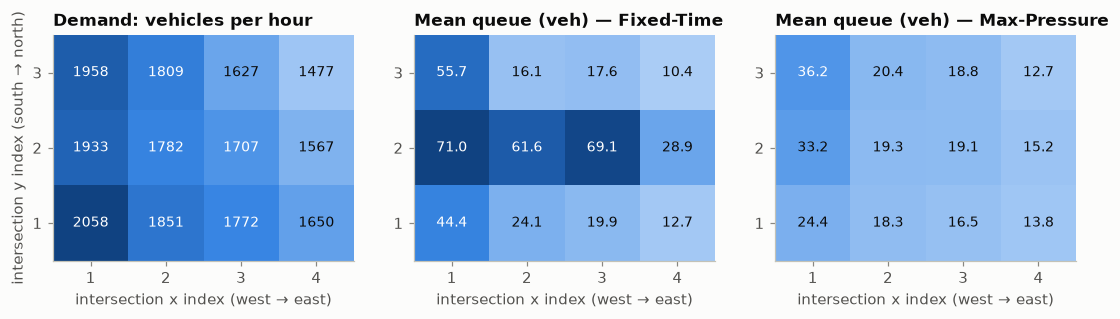

movements east/west-bound: 10795, north/south-bound: 10396
entry demand, busiest / quietest: 675 / 257
fixed_time mean queue per intersection: min 10.4 max 71.0 | corr with demand 0.53
max_pressure mean queue per intersection: min 12.7 max 36.2 | corr with demand 0.76


In [9]:
def grid(series):
    g = np.full((3, 4), np.nan)
    for iid, value in series.items():
        _, x, y = iid.split("_")
        g[int(y) - 1, int(x) - 1] = value
    return g

mean_queue = {c: runs[c]["steps"].assign(q=runs[c]["steps"].filter(regex=r"^queue_").sum(axis=1))
              .groupby("intersection")["q"].mean() for c in ("fixed_time", "max_pressure")}
vmax = max(s.max() for s in mean_queue.values())
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
specs = [(grid(load), "Demand: vehicles per hour", None, "{:.0f}"),
         (grid(mean_queue["fixed_time"]), "Mean queue (veh) — Fixed-Time", vmax, "{:.1f}"),
         (grid(mean_queue["max_pressure"]), "Mean queue (veh) — Max-Pressure", vmax, "{:.1f}")]
for ax, (g, title, top, fmt) in zip(axes, specs):
    im = ax.imshow(g, cmap=SEQ, origin="lower", vmin=0 if top else g.min() * 0.9, vmax=top or g.max())
    mid = (im.norm.vmin + im.norm.vmax) / 2
    for (r, c), value in np.ndenumerate(g):
        ax.text(c, r, fmt.format(value), ha="center", va="center", fontsize=9,
                color="white" if value > mid else INK)
    ax.set_xticks(range(4), labels=[1, 2, 3, 4])
    ax.set_yticks(range(3), labels=[1, 2, 3])
    ax.set(title=title, xlabel="intersection x index (west → east)")
    ax.grid(False)
axes[0].set_ylabel("intersection y index (south → north)")
save_figure(fig, FIG / "08_load_imbalance.png")
plt.show()

ew = moves[moves["approach"].isin(["E", "W"])]["vehicles"].sum()
ns = moves[moves["approach"].isin(["N", "S"])]["vehicles"].sum()
print(f"movements east/west-bound: {ew}, north/south-bound: {ns}")
print("entry demand, busiest / quietest:", entry.iloc[0], "/", entry.iloc[-1])
for c, s in mean_queue.items():
    print(c, "mean queue per intersection: min %.1f max %.1f" % (s.min(), s.max()),
          "| corr with demand %.2f" % np.corrcoef(s.sort_index(), load.sort_index())[0, 1])

*Figure 8. Left: vehicles per hour passing through each intersection (demand, from the flow file). Middle and right: mean number of waiting vehicles on the 12 incoming lanes of each intersection over the episode, under Fixed-Time and Max-Pressure (same colour scale). Each cell is one intersection at its grid position.*

**Interpretation.** Demand per intersection differs by a factor of 1.4 (1,477 to 2,058
vehicles per hour) and decreases from west to east. Queues do not simply follow demand. Under
Fixed-Time the middle row holds 62–71 waiting vehicles at three intersections while most
others hold 10–25 (correlation with demand 0.53). Under Max-Pressure queues are smaller and
more even (13–36 vehicles; correlation with demand 0.76), with the western column highest.
So where congestion forms depends on the controller and on how neighbouring signals release
vehicles, not only on local demand. Results should therefore be broken down per intersection
(planned in the error analysis, ROADMAP 8.4), not reported only as a network average.

## 9. Reward sanity check: pressure versus queue

The provisional reward is the negative absolute intersection pressure,
r_i = −|P_i| with P_i = (vehicles on incoming lanes) − (vehicles on outgoing lanes).
The quantity we care about is congestion (queues, travel time). This section checks on the
training traces that the two move together.

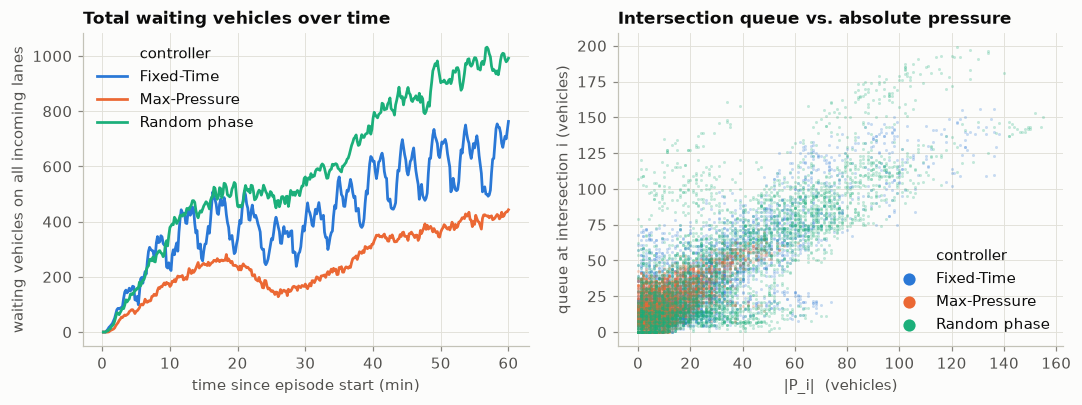

,"corr(queue_i, |P_i|), all samples",corr per intersection: min,corr per intersection: max,"corr(network queue, Σ|P_i|) over time",mean |P_i| (veh),mean queue_i (veh),share of samples with P_i < 0
Fixed-Time,0.82,-0.18,0.94,0.86,24.78,35.96,0.30
Max-Pressure,0.65,0.13,0.87,0.85,11.12,20.67,0.22
Random phase,0.77,-0.36,0.96,0.97,35.64,49.44,0.29


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
rows = {}
for c in runs:
    steps = runs[c]["steps"]
    net = eda.network_series(steps)
    axes[0].plot(net.index / 60, net["queue"], color=CONTROLLER_COLOR[c], label=CONTROLLER_LABEL[c])
    q_i = steps.filter(regex=r"^queue_").sum(axis=1)
    p_i = steps["pressure"].abs()
    axes[1].scatter(p_i, q_i, s=4, alpha=0.25, color=CONTROLLER_COLOR[c], label=CONTROLLER_LABEL[c],
                    linewidths=0)
    per_inter = steps.assign(q=q_i, p=p_i).groupby("intersection")[["q", "p"]].corr().unstack().iloc[:, 1]
    rows[CONTROLLER_LABEL[c]] = {
        "corr(queue_i, |P_i|), all samples": np.corrcoef(q_i, p_i)[0, 1],
        "corr per intersection: min": per_inter.min(), "corr per intersection: max": per_inter.max(),
        "corr(network queue, Σ|P_i|) over time": np.corrcoef(net["queue"], net["abs_pressure"])[0, 1],
        "mean |P_i| (veh)": p_i.mean(), "mean queue_i (veh)": q_i.mean(),
        "share of samples with P_i < 0": (steps["pressure"] < 0).mean(),
    }
axes[0].set(title="Total waiting vehicles over time", xlabel="time since episode start (min)",
            ylabel="waiting vehicles on all incoming lanes")
axes[0].legend(title="controller")
axes[1].set(title="Intersection queue vs. absolute pressure",
            xlabel="|P_i|  (vehicles)", ylabel="queue at intersection i (vehicles)")
leg = axes[1].legend(title="controller", markerscale=4)
for h in leg.legend_handles:
    h.set_alpha(1)
save_figure(fig, FIG / "09_reward_check.png")
plt.show()
display(pd.DataFrame(rows).T)

*Figure 9 and Table 9. Left: number of waiting vehicles in the network over the episode under each controller. Right: one point per (intersection, time) sample — queue on the incoming lanes against the absolute pressure |P_i| that the reward penalises.*

**Interpretation.** *Left:* the number of waiting vehicles grows over the hour under every
controller (to about 440 under Max-Pressure, 760 under Fixed-Time and 1,000 under random
control), with a dip after the low-demand minutes 20–24. The network does not reach a steady
state within the episode, so results depend on the episode length and a backlog remains at
the end. *Right:* intersection queue and absolute pressure are positively related: the
correlation is 0.65–0.82 over all samples and 0.85–0.97 for network totals over time. The
relation is not exact. For single intersections the correlation ranges from −0.36 to 0.96;
22–30 % of samples have negative pressure (more vehicles downstream than upstream); and the
scatter shows samples with 100–150 waiting vehicles at a pressure near zero. Pressure is
small when the incoming *and* the outgoing lanes are both full, which is a congested state
that the reward −|P_i| does not penalise. Conclusion: −pressure is a usable training signal
and keeps the work comparable with PressLight / CoLight, but it is a proxy. Models are
compared on travel time, queue and wait, never on reward, and −queue remains the alternative
to consider at the protocol freeze (ROADMAP 3.5).

## 10. Decision-interval sanity check and seed effect

Max-Pressure on the training flow with a decision every Δt ∈ {5, 10, 15, 20} s (5 s
transition on every phase change), and each rule controller repeated with seeds 0, 1, 2.

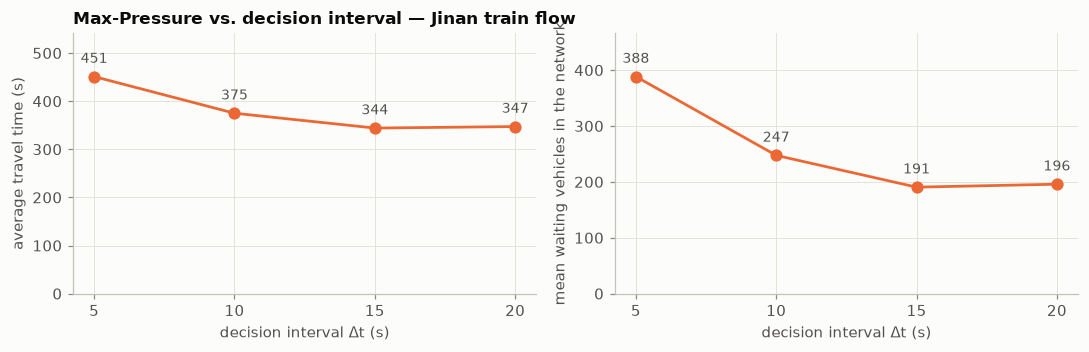

,avg_travel_time_s,mean_total_queue,completed,phase_switches,never_entered
interval_s,,,,,
5,451.12,388.42,5063,3326,0
10,374.94,247.41,5446,2484,0
15,344.13,190.56,5605,1976,0
20,347.26,195.84,5635,1612,0


seed,0,1,2,std
controller,,,,
fixed_time,515.21,515.21,515.21,0
max_pressure,374.94,374.94,374.94,0
random,645.75,656.74,650.21,5.53


In [11]:
sweep = summaries[(summaries["controller"] == "max_pressure") & (summaries["seed"] == cfg["seed"])]
sweep = sweep.sort_values("interval_s")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, (col, label) in zip(axes, [("avg_travel_time_s", "average travel time (s)"),
                                   ("mean_total_queue", "mean waiting vehicles in the network")]):
    ax.plot(sweep["interval_s"], sweep[col], color=ORANGE, marker="o", markersize=7)
    for x, y in zip(sweep["interval_s"], sweep[col]):
        ax.annotate(f"{y:.0f}", (x, y), xytext=(0, 9), textcoords="offset points", ha="center",
                    fontsize=9, color=INK_SECONDARY)
    ax.set(xlabel="decision interval Δt (s)", ylabel=label, xticks=sweep["interval_s"],
           ylim=(0, sweep[col].max() * 1.2))
axes[0].set_title("Max-Pressure vs. decision interval — Jinan train flow")
fig.tight_layout()
save_figure(fig, FIG / "10_decision_interval.png")
plt.show()
display(sweep.set_index("interval_s")[["avg_travel_time_s", "mean_total_queue", "completed",
                                       "phase_switches", "never_entered"]])

main = summaries[summaries["run"].isin([f"{n[:-1]}{s}" for n in RUN_NAME.values()
                                        for s in cfg["eda"]["seeds"]])]
seed_table = main.pivot(index="controller", columns="seed", values="avg_travel_time_s")
seed_table["std"] = seed_table.std(axis=1, ddof=1)
display(seed_table)

*Figure 10 and Table 10a. Max-Pressure on the training flow for four decision intervals (seed 0). Table 10b. Average travel time (s) of each rule controller for seeds 0, 1, 2.*

**Interpretation.** *Decision interval.* For Max-Pressure on the training flow the average
travel time is 451 s at Δt = 5 s, 375 s at 10 s, 344 s at 15 s and 347 s at 20 s. Short
intervals lose green time to transitions: 3,326 phase changes at 5 s against 1,612 at 20 s,
each costing 5 s in which only right turns move. The provisional Δt = 10 s is therefore not
the best value for Max-Pressure on this flow; 15 s is 8 % better. This is one rule controller
on one hour, so it does not show what is best for a learned policy, but it is evidence that
the choice matters. It is recorded as an open point for the protocol freeze (see insights).

*Seed effect.* Fixed-Time and Max-Pressure give identical results for seeds 0, 1 and 2
(standard deviation 0): with a fixed flow file and a deterministic controller, the simulator
is deterministic. Random control varies (646–657 s, standard deviation 5.5 s) only because its
actions are random. For the evaluation this means that the rule-based baselines have no
seed variance, and that the confidence intervals of the RL agents measure training and
exploration randomness, not variation in traffic.

## Insights that shaped later choices

| # | Finding (training flow only) | Consequence |
|---|---|---|
| 1 | No lane exceeds 96 % of its capacity under any controller, including random control (§6). | Observations are normalised by **lane capacity** (length / 7.5 m). Nothing is fitted, so no statistic can leak from other splits, and the same rule applies to another city's road lengths. |
| 2 | Queues sit on through lanes; right-turn lanes are almost always empty (§6, §7). | The 44-value observation keeps all 12 lanes for a uniform layout across intersections; the feature groups stay selectable in the config in case a smaller state is tried on validation. |
| 3 | Demand changes in five-minute blocks, from 3,000 to 8,160 vehicles per hour (§3). | A decision interval of 10–20 s is short compared with demand changes. One episode contains several demand levels, so a single hour already tests adaptation. |
| 4 | Travel time is right-skewed and 13–21 % of trips do not finish within the hour (§4). | Report **throughput and maximum wait** next to the average travel time (already in `PRD.md` §5); never the mean alone. |
| 5 | Queues grow throughout the hour; there is no steady state (§9). | Results depend on episode length, so the episode length is part of the frozen protocol and identical for every agent (3,600 s, the full flow file). |
| 6 | Pressure and queue are correlated (0.65–0.82) but pressure is near zero when both upstream and downstream lanes are full (§9). | Keep **reward = −pressure** (user decision, literature convention) as a proxy; evaluate only on traffic metrics. −queue is the documented alternative for the freeze. |
| 7 | Max-Pressure is 8 % better at Δt = 15 s than at 10 s; 5 s is clearly worse (§10). | Δt = 10 s is not contradicted as a workable value, but 15 s is at least as good here. **Open decision for the protocol freeze (3.5):** keep 10 s for comparability with the literature, switch to 15 s, or tune Max-Pressure's interval on validation as its own hyperparameter so the baseline is not handicapped. |
| 8 | Rule controllers are deterministic across seeds (§10). | Fixed-Time and Max-Pressure are reported without a confidence interval (one deterministic value); the intervals of RL agents reflect training randomness only. To be stated in the evaluation protocol. |
| 9 | Load differs by a factor of 1.4 between columns, and queue location depends on the controller (§2, §8). | Per-intersection breakdown in the error analysis; neighbour information is plausibly useful, to be tested by the −attention ablation. |

**Limits of this EDA.** One flow file (one hour) and three rule controllers; the feature
ranges under a learning agent may differ. Statements about what will help the learned model
(points 2, 9 and the remark in §6) are expectations to be tested, not results. Validation,
test and held-out data were not examined.